
# Marco 1 — Classificação de Registros de Doença Renal Crônica

**Disciplina:** Aprendizagem de Máquina — ADS033  
**Curso:** Análise e Desenvolvimento de Sistemas - IESB

## Apresentação do projeto

Neste projeto, utilizamos uma base de dados com informações clínicas e laboratoriais de pacientes para desenvolver um processo de aprendizagem de máquina aplicado à classificação de registros relacionados à doença renal crônica (DRC).

O trabalho envolve a análise e preparação dos dados, além do desenvolvimento e da avaliação de um modelo de referência (*baseline*).

A classificação considera duas categorias presentes na base: `ckd` (com DRC) e `notckd` (sem DRC registrada). O objetivo é classificar os registros existentes, não prever o desenvolvimento futuro da doença nem realizar diagnósticos clínicos.

## Objetivos do Marco 1

- Conhecer e analisar a base de dados.
- Realizar a análise exploratória (EDA).
- Limpar e preparar os dados.
- Definir e executar a divisão entre treinamento, validação e teste.
- Desenvolver e avaliar um modelo baseline.


## Observação sobre a base

A base utilizada possui 400 registros e foi autorizada pelo professor Rodrigo.

## Integrantes
- João Emanuel Pinheiro - 2514290006
- Iago de Oliveira Rodrigues - 2514290017
- Nithielly Tamily Carvalho dos Santos -  2624290012

- Gabriel Santana Oliveira Silva - 2514290016


---

## 1. Conhecimento e descrição da base de dados

### 1.1 Origem da base

Foi utilizada a base **Chronic Kidney Disease (CKD)**, disponibilizada pelo UCI Machine Learning Repository.

A base possui 400 registros e 25 colunas, sendo 24 atributos clínicos e laboratoriais e uma variável-alvo (`class`).

**Fonte:** [UCI Machine Learning Repository — CKD](https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease)

**Licença:** CC BY 4.0.

In [ ]:

from pathlib import Path
from urllib.request import urlretrieve
import hashlib

# Identifica o ambiente de execução
try:
    import google.colab
    ROOT = Path('/content/marco1_doenca_renal')
except ImportError:
    ROOT = Path.cwd() / 'marco1_colab_dados'

# Cria a pasta e define o arquivo
data_dir = ROOT / 'data'
data_dir.mkdir(parents=True, exist_ok=True)

data_path = data_dir / 'ckd_uci.csv'
source_url = 'https://archive.ics.uci.edu/static/public/336/data.csv'

# Baixa a base caso ela ainda não exista
if not data_path.exists():
    print('Realizando download da base de dados...')
    urlretrieve(source_url, data_path)
else:
    print('Arquivo já disponível. Verificando integridade...')

# Verifica a integridade do arquivo com SHA-256
expected_sha256 = (
    '0eeea8d17f5ad8792d854999d6ddf1602'
    'ec4e116616f6ccdfdaef0ba8109e694'
)
actual_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()

if actual_sha256 != expected_sha256:
    raise ValueError('A base apresenta divergência em relação à versão verificada.')

print('Base disponível e integridade verificada com sucesso!')
print('Diretório do projeto:', ROOT)
print('Arquivo:', data_path)


Arquivo já disponível. Verificando integridade...
Base disponível e integridade verificada com sucesso!
Diretório do projeto: /content/marco1_doenca_renal
Arquivo: /content/marco1_doenca_renal/data/ckd_uci.csv


### 1.2 Inspeção inicial da base de dados

Após obter a base, realizamos sua leitura e inspeção inicial utilizando a biblioteca Pandas. Por meio de `pd.read_csv()`, carregamos o arquivo CSV e organizamos os dados em um DataFrame.

Durante a importação, utilizamos `dtype=str` para carregar inicialmente todas as informações como texto. Essa escolha permite realizar conversões controladas dos atributos numéricos posteriormente, durante a limpeza dos dados.

Em seguida, utilizamos `shape`, `columns` e `head()` para verificar as dimensões da base, conferir os nomes das colunas e visualizar os primeiros registros.

A inspeção confirmou 400 registros e 25 colunas, sendo 24 atributos e uma variável-alvo (`class`). Também verificamos se a variável-alvo estava presente e se os nomes das colunas eram únicos.

Na visualização inicial, identificamos campos sem preenchimento, representados pelo Pandas como `NaN`. Essa constatação indicou a necessidade de investigar os valores ausentes antes do treinamento dos modelos.

In [ ]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Carrega a base como texto para permitir conversões controladas
raw = pd.read_csv(data_path, dtype=str)

# Confere a estrutura e a identificação das variáveis
assert raw.shape == (400, 25), f"Dimensão inesperada: {raw.shape}"
assert 'class' in raw.columns, "Variável-alvo não encontrada."
assert raw.columns.is_unique, "Existem nomes de colunas duplicados."

# Apresenta a estrutura da base
print("Dimensão da base:", raw.shape)
print("Variáveis disponíveis:", raw.columns.tolist())
display(raw.head())

print("Base carregada e validada com sucesso!")


Dimensão da base: (400, 25)
Variáveis disponíveis: ['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48,80,1.02,1,0,NaN,normal,notpresent,notpresent,121,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7,50,1.02,4,0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62,80,1.01,2,3,normal,normal,notpresent,notpresent,423,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48,70,1.005,4,0,normal,abnormal,present,notpresent,117,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51,80,1.01,2,0,normal,normal,notpresent,notpresent,106,...,35,7300,4.6,no,no,no,good,no,no,ckd


Base carregada e validada com sucesso!


### 1.3 Dicionário das variáveis

Após identificar a estrutura da base, organizamos suas 25 variáveis em um dicionário utilizando Python. Para cada coluna, registramos sua descrição, classificação quanto ao tipo de dado (numérico ou categórico) e unidade de medida ou categorias possíveis. Essa organização permite compreender melhor as informações disponíveis e facilita sua utilização nas próximas etapas.

Para estruturar esses dados, utilizamos `dict()` e `zip()`, relacionando cada variável às suas respectivas informações. Em seguida, com o Pandas, utilizamos `pd.DataFrame.from_dict()` para transformar o dicionário em uma tabela, facilitando a consulta e a visualização das características de cada atributo.

Também utilizamos `assert` para conferir se todas as colunas da base original estavam contempladas no dicionário. Essa verificação ajuda a evitar inconsistências na identificação das variáveis.

Por fim, separamos os atributos em duas listas: numéricos (`num`) e categóricos (`cat`), utilizando compreensões de lista. A variável `class` foi mantida separadamente como variável-alvo (`target`), pois representa a classificação que será utilizada pelos modelos de aprendizagem de máquina.

Ao final, foram identificadas 25 variáveis, sendo 11 atributos numéricos, 13 categóricos e uma variável-alvo. A tabela gerada apresenta suas respectivas descrições, tipos e unidades ou categorias.

In [ ]:

# Dicionário das 25 variáveis: significado, tipo e unidade/categorias
dados_variaveis = {
    'age': ('Idade do paciente', 'Numérica', 'Anos'),
    'bp': ('Pressão arterial', 'Numérica', 'mm/Hg'),
    'sg': ('Densidade específica urinária', 'Categórica', '1.005 a 1.025'),
    'al': ('Nível de albumina', 'Categórica', 'Níveis de 0 a 5'),
    'su': ('Nível de açúcar na urina', 'Categórica', 'Níveis de 0 a 5'),
    'rbc': ('Normalidade das hemácias', 'Categórica', 'normal / abnormal'),
    'pc': ('Normalidade das células de pus', 'Categórica', 'normal / abnormal'),
    'pcc': ('Aglomerados de células de pus', 'Categórica', 'present / notpresent'),
    'ba': ('Presença de bactérias', 'Categórica', 'present / notpresent'),
    'bgr': ('Glicose sanguínea casual', 'Numérica', 'mg/dL'),
    'bu': ('Ureia sanguínea', 'Numérica', 'mg/dL'),
    'sc': ('Creatinina sérica', 'Numérica', 'mg/dL'),
    'sod': ('Nível de sódio', 'Numérica', 'mEq/L'),
    'pot': ('Nível de potássio', 'Numérica', 'mEq/L'),
    'hemo': ('Nível de hemoglobina', 'Numérica', 'gms, conforme UCI'),
    'pcv': ('Volume globular (hematócrito)', 'Numérica', 'Não especificada pela UCI'),
    'wbcc': ('Contagem de leucócitos', 'Numérica', 'cells/cumm'),
    'rbcc': ('Contagem de hemácias', 'Numérica', 'millions/cmm'),
    'htn': ('Presença de hipertensão', 'Categórica', 'yes / no'),
    'dm': ('Presença de diabetes mellitus', 'Categórica', 'yes / no'),
    'cad': ('Doença arterial coronariana', 'Categórica', 'yes / no'),
    'appet': ('Condição do apetite', 'Categórica', 'good / poor'),
    'pe': ('Presença de edema pedal', 'Categórica', 'yes / no'),
    'ane': ('Presença de anemia', 'Categórica', 'yes / no'),
    'class': ('Classificação da doença renal crônica',
              'Categórica (variável-alvo)', 'ckd / notckd')
}

# Organiza as informações e gera a tabela
campos = ['significado', 'tipo', 'unidade']
dicionario = {
    coluna: dict(zip(campos, valores))
    for coluna, valores in dados_variaveis.items()
}

tabela_variaveis = (
    pd.DataFrame.from_dict(dicionario, orient='index')
    .rename_axis('Variável')
    .rename(columns={
        'significado': 'Significado',
        'tipo': 'Tipo',
        'unidade': 'Unidade / categorias'
    })
    .reset_index()
)

# Confere se todas as colunas da base estão documentadas
assert set(raw.columns) == set(dicionario), (
    'As variáveis do dicionário não correspondem às colunas da base.'
)

# Separa os atributos numéricos, categóricos e a variável-alvo
num = [c for c, info in dicionario.items() if info['tipo'] == 'Numérica']
cat = [c for c, info in dicionario.items()
       if info['tipo'] == 'Categórica' and c != 'class']
target = 'class'

print(f'Total de variáveis: {len(dicionario)}')
print(f'Atributos numéricos: {len(num)}')
print(f'Atributos categóricos: {len(cat)}')
print(f'Variável-alvo: {target}')

display(tabela_variaveis)


Total de variáveis: 25
Atributos numéricos: 11
Atributos categóricos: 13
Variável-alvo: class


,Variável,Significado,Tipo,Unidade / categorias
0,age,Idade do paciente,Numérica,Anos
1,bp,Pressão arterial,Numérica,mm/Hg
2,sg,Densidade específica urinária,Categórica,1.005 a 1.025
3,al,Nível de albumina,Categórica,Níveis de 0 a 5
4,su,Nível de açúcar na urina,Categórica,Níveis de 0 a 5
5,rbc,Normalidade das hemácias,Categórica,normal / abnormal
6,pc,Normalidade das células de pus,Categórica,normal / abnormal
7,pcc,Aglomerados de células de pus,Categórica,present / notpresent
8,ba,Presença de bactérias,Categórica,present / notpresent
9,bgr,Glicose sanguínea casual,Numérica,mg/dL


## 2. Limpeza e auditoria dos dados

Com o **Pandas**, realizamos a limpeza e a verificação da consistência dos dados. Primeiro, criamos uma cópia da base original (`df = raw.copy()`), preservando os dados importados e permitindo trabalhar sobre uma versão independente.

Utilizamos `strip()` para remover espaços desnecessários dos textos e `replace()` para identificar representações de campos vazios, como `?` e strings sem conteúdo, convertendo-as em valores ausentes (`NaN`).

Para os atributos numéricos, aplicamos `pd.to_numeric()` com `errors='coerce'`, convertendo os valores válidos para o formato numérico e identificando conteúdos que não poderiam ser convertidos.

Também verificamos se a variável-alvo continha apenas as categorias esperadas (`ckd` e `notckd`), conferimos os valores das variáveis categóricas e procuramos registros duplicados.

Por fim, reunimos essas verificações em um relatório de auditoria, com informações sobre valores ausentes, conversões numéricas, categorias inesperadas e duplicatas. Os valores ausentes foram mantidos para serem tratados posteriormente no pré-processamento, evitando a exclusão prematura de registros que ainda poderiam ser aproveitados.

In [ ]:

# Prepara a pasta de resultados
OUT = ROOT / 'resultados'
OUT.mkdir(parents=True, exist_ok=True)

# Cria uma cópia e padroniza os valores vazios
df = raw.copy()
df = df.apply(lambda col: col.str.strip() if col.dtype == 'object' else col)
df = df.replace({'?': np.nan, '': np.nan})

# Converte os atributos numéricos e registra possíveis erros
conversoes_invalidas = {}

for col in num:
    original = df[col]
    df[col] = pd.to_numeric(original, errors='coerce')

    invalidos = original.notna() & df[col].isna()
    conversoes_invalidas[col] = {
        'quantidade': int(invalidos.sum()),
        'valores': original[invalidos].unique().tolist()
    }

# Valida a variável-alvo
rotulos_validos = {'ckd', 'notckd'}
rotulos_invalidos = set(df[target].dropna().unique()) - rotulos_validos

assert df[target].notna().all(), 'Existem classificações ausentes.'
assert not rotulos_invalidos, f'Rótulos desconhecidos: {rotulos_invalidos}'

# Confere os valores permitidos nas variáveis categóricas
categorias_esperadas = {
    'sg': {1.005, 1.010, 1.015, 1.020, 1.025},
    'al': set(range(6)), 'su': set(range(6)),
    'rbc': {'normal', 'abnormal'}, 'pc': {'normal', 'abnormal'},
    'pcc': {'present', 'notpresent'}, 'ba': {'present', 'notpresent'},
    'htn': {'yes', 'no'}, 'dm': {'yes', 'no'}, 'cad': {'yes', 'no'},
    'appet': {'good', 'poor'}, 'pe': {'yes', 'no'}, 'ane': {'yes', 'no'}
}

categorias_invalidas = {}

for col, validas in categorias_esperadas.items():
    valores = pd.to_numeric(df[col], errors='coerce') if col in ['sg', 'al', 'su'] else df[col]
    mascara = df[col].notna() & (valores.isna() | ~valores.isin(validas))
    categorias_invalidas[col] = df.loc[mascara, col].astype(str).unique().tolist()

# Identifica e remove registros duplicados
duplicatas = int(df.duplicated().sum())
df = df.drop_duplicates()

# Calcula os valores ausentes e lista as categorias encontradas
ausencias = pd.DataFrame({
    'Quantidade': df.isna().sum(),
    'Percentual (%)': (df.isna().mean() * 100).round(2)
})

categorias = pd.DataFrame({
    'Variável': cat + [target],
    'Categorias': [
        ', '.join(df[col].dropna().astype(str).unique())
        for col in cat + [target]
    ]
})

# Monta e salva o relatório de auditoria
auditoria = {
    'registros_originais': len(raw),
    'duplicatas_removidas': duplicatas,
    'registros_finais': len(df),
    'conversoes_invalidas': conversoes_invalidas,
    'categorias_invalidas': categorias_invalidas,
    'valores_ausentes': {
        col: int(qtd) for col, qtd in df.isna().sum().items()
    },
    'total_ausentes': int(df.isna().sum().sum()),
    'colunas_descartadas': [],
    'linhas_descartadas_por_ausencia': 0,
    'outliers_removidos': 0
}

(OUT / 'auditoria.json').write_text(
    json.dumps(auditoria, indent=4, ensure_ascii=False),
    encoding='utf-8'
)

# Apresenta o resumo da auditoria
print('RESUMO DA LIMPEZA E AUDITORIA')
print('-' * 40)
print('Registros originais:', len(raw))
print('Duplicatas removidas:', duplicatas)
print('Registros finais:', len(df))
print('Total de valores ausentes:', int(df.isna().sum().sum()))
print('Conversões numéricas inválidas:',
      sum(v['quantidade'] for v in conversoes_invalidas.values()))

print('\nValores ausentes por variável:')
display(ausencias)

print('\nCategorias encontradas:')
display(categorias)

print('\nDistribuição da variável-alvo:')
display(df[target].value_counts().to_frame('Quantidade'))

if any(categorias_invalidas.values()):
    print('\nATENÇÃO: existem categorias inesperadas:', categorias_invalidas)
else:
    print('\nTodas as categorias estão dentro dos valores esperados.')

print('\nAuditoria salva em:', OUT / 'auditoria.json')


RESUMO DA LIMPEZA E AUDITORIA
----------------------------------------
Registros originais: 400
Duplicatas removidas: 0
Registros finais: 400
Total de valores ausentes: 1012
Conversões numéricas inválidas: 0

Valores ausentes por variável:


,Quantidade,Percentual (%)
age,9,2.25
bp,12,3.00
sg,47,11.75
al,46,11.50
su,49,12.25
rbc,152,38.00
pc,65,16.25
pcc,4,1.00
ba,4,1.00
bgr,44,11.00



Categorias encontradas:


,Variável,Categorias
0,sg,"1.02, 1.01, 1.005, 1.015, 1.025"
1,al,"1, 4, 2, 3, 0, 5"
2,su,"0, 3, 4, 1, 2, 5"
3,rbc,"normal, abnormal"
4,pc,"normal, abnormal"
5,pcc,"notpresent, present"
6,ba,"notpresent, present"
7,htn,"yes, no"
8,dm,"yes, no"
9,cad,"no, yes"



Distribuição da variável-alvo:


,Quantidade
class,
ckd,250
notckd,150



Todas as categorias estão dentro dos valores esperados.

Auditoria salva em: /content/marco1_doenca_renal/resultados/auditoria.json


### 2.1 Resultados da auditoria

Após a execução das verificações, a auditoria confirmou que a base permaneceu com os 400 registros originais. Não foram identificadas duplicatas, conversões numéricas inválidas ou categorias fora dos valores esperados. Dessa forma, não foi necessário remover registros ou atributos durante essa etapa.

Em relação aos valores ausentes, foram identificados 1.012 campos sem preenchimento, distribuídos entre as variáveis da base. As maiores proporções foram encontradas em `rbc` (38%), `rbcc` (32,75%) e `wbcc` (26,5%). Esses percentuais representam a proporção de registros sem informação em cada variável, e não a quantidade total de pacientes.

Optamos por preservar os registros e deixar o tratamento dos valores ausentes para a etapa de pré-processamento. Essa decisão evita a perda desnecessária de informações, permitindo que os campos vazios sejam preenchidos posteriormente por técnicas adequadas a cada tipo de variável.

Quanto à variável-alvo, foram identificados 250 registros classificados como `ckd` e 150 como `notckd`, correspondendo a 62,5% e 37,5% do conjunto, respectivamente. Essa distribuição demonstra uma diferença na quantidade de registros entre as classes, aspecto que deverá ser considerado durante a avaliação dos modelos.

## 3. Protocolo experimental

Com o Scikit-learn, definimos a divisão da base em três conjuntos, utilizando a função `train_test_split()` em duas etapas. Inicialmente, reservamos 20% dos registros para o teste, mantendo os 80% restantes para desenvolvimento. Em seguida, dividimos esse conjunto de desenvolvimento, destinando 75% para treinamento e 25% para validação. Dessa forma, obtivemos a proporção final de 60%, 20% e 20%.

- **Treinamento (60%):** utilizado para ajustar os modelos e os procedimentos de pré-processamento.
- **Validação (20%):** utilizado para comparar os resultados e orientar as decisões durante o desenvolvimento.
- **Teste (20%):** reservado para a avaliação final dos modelos.

Nas duas divisões, utilizamos a estratificação (`stratify`), que preserva a proporção entre as classes nos diferentes conjuntos. Também definimos `random_state=42`, garantindo que a divisão possa ser reproduzida em novas execuções.

Os atributos preditores foram separados da variável-alvo, que foi codificada numericamente, atribuindo 1 à classe `ckd` e 0 à classe `notckd`. Além disso, verificamos a independência das partições por meio dos índices dos registros e registramos essas informações no arquivo `indices_particoes.json`, permitindo recuperar a divisão utilizada no experimento.

Os procedimentos de pré-processamento foram ajustados exclusivamente com os dados de treinamento e posteriormente aplicados aos conjuntos de validação e teste. Esse cuidado evita o vazamento de informações (*data leakage*), impedindo que informações dos dados reservados influenciem o aprendizado dos modelos.

Como a base não possui identificadores individuais ou datas dos exames, adotamos uma divisão aleatória. Essa escolha representa uma limitação, pois não permite considerar possíveis relações entre registros de um mesmo paciente ou a ordem temporal dos exames.

In [ ]:

from sklearn.model_selection import train_test_split

# Define a semente e separa os atributos da variável-alvo
SEED = 42

X = df[num + cat].copy()
y = df[target].map({'ckd': 1, 'notckd': 0}).astype(int)

# Separa 20% para teste e 80% para desenvolvimento
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# Divide os 80% restantes em treinamento (60%) e validação (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev
)

# Verifica se os conjuntos não compartilham registros
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(df)

# Gera o resumo das partições
particoes = {
    'Treinamento': y_train,
    'Validação': y_val,
    'Teste': y_test
}

resumo = pd.DataFrame([
    {
        'Conjunto': nome,
        'Registros': len(rotulos),
        'CKD': int((rotulos == 1).sum()),
        'notCKD': int((rotulos == 0).sum()),
        'CKD (%)': round(rotulos.mean() * 100, 2)
    }
    for nome, rotulos in particoes.items()
])

# Salva os índices utilizados em cada conjunto
indices = {
    'semente': SEED,
    'treinamento': [int(i) for i in X_train.index],
    'validacao': [int(i) for i in X_val.index],
    'teste': [int(i) for i in X_test.index]
}

(OUT / 'indices_particoes.json').write_text(
    json.dumps(indices, indent=4), encoding='utf-8'
)

print('DIVISÃO DOS DADOS')
print('-' * 40)
print('Semente aleatória:', SEED)
display(resumo)

print('\nNenhum registro foi compartilhado entre os conjuntos.')
print('Divisão concluída com sucesso!')


DIVISÃO DOS DADOS
----------------------------------------
Semente aleatória: 42


,Conjunto,Registros,CKD,notCKD,CKD (%)
0,Treinamento,240,150,90,62.5
1,Validação,80,50,30,62.5
2,Teste,80,50,30,62.5



Nenhum registro foi compartilhado entre os conjuntos.
Divisão concluída com sucesso!


### 3.1 Resultado da divisão dos dados

A divisão gerou os seguintes quantitativos:

- **Treinamento:** 240 registros, sendo 150 `ckd` e 90 `notckd`.
- **Validação:** 80 registros, sendo 50 `ckd` e 30 `notckd`.
- **Teste:** 80 registros, sendo 50 `ckd` e 30 `notckd`.

Os três conjuntos mantiveram a proporção de 62,5% de registros `ckd` e 37,5% de `notckd`, conforme planejado.

Também verificamos que não existem índices compartilhados entre as partições, garantindo que nenhum registro esteja presente em mais de um conjunto.

O resultado confirma que a divisão foi realizada conforme o protocolo estabelecido, mantendo o conjunto de teste reservado para a avaliação final.

## 4. Análise exploratória dos dados (EDA)

Realizamos a análise exploratória utilizando os dados de treinamento (`X_train`), buscando compreender as características e o comportamento das variáveis antes da construção dos modelos.

Nas etapas seguintes, investigamos os atributos numéricos e categóricos, possíveis valores atípicos, relações entre as variáveis e a distribuição da variável-alvo. Para isso, utilizamos medidas estatísticas, tabelas e representações gráficas que facilitam a visualização e interpretação dos dados.

Toda a análise foi concentrada no conjunto de treinamento, mantendo os dados de validação e teste reservados.

### 4.1 Estatísticas descritivas dos atributos numéricos

Inicialmente, analisamos os atributos numéricos por meio de medidas estatísticas. Utilizamos `describe()` para obter um resumo dos dados, incluindo quantidade de observações, média, desvio padrão, valores mínimos e máximos e quartis. Complementamos essas informações com o cálculo da moda, variância, amplitude e intervalo interquartil (IQR).

Também verificamos a quantidade e o percentual de valores ausentes em cada variável, permitindo identificar quais atributos apresentavam informações incompletas no conjunto de treinamento.

Essas medidas possibilitam observar onde os dados estão concentrados, o quanto estão dispersos e como se distribuem. Além disso, fornecem informações importantes para compreender as características dos atributos antes da aplicação dos modelos de aprendizagem de máquina.

In [ ]:

# Calcula as estatísticas dos atributos numéricos
dados_num = X_train[num]
estatisticas = dados_num.describe().T

# Acrescenta medidas de posição e dispersão
estatisticas['Moda'] = dados_num.mode().iloc[0]
estatisticas['Variância'] = dados_num.var()
estatisticas['Amplitude'] = dados_num.max() - dados_num.min()
estatisticas['IQR'] = estatisticas['75%'] - estatisticas['25%']

# Calcula os valores ausentes
estatisticas['Ausentes'] = dados_num.isna().sum()
estatisticas['Ausentes (%)'] = dados_num.isna().mean() * 100

# Organiza e apresenta a tabela
estatisticas = estatisticas.rename(columns={
    'count': 'Observados',
    'mean': 'Média',
    'std': 'Desvio padrão',
    'min': 'Mínimo',
    '25%': 'Q1',
    '50%': 'Mediana',
    '75%': 'Q3',
    'max': 'Máximo'
})

estatisticas = estatisticas[
    ['Observados', 'Ausentes', 'Ausentes (%)',
     'Média', 'Mediana', 'Moda', 'Variância',
     'Desvio padrão', 'Mínimo', 'Q1', 'Q3',
     'Máximo', 'Amplitude', 'IQR']
].round(2)

# Salva e exibe os resultados
estatisticas.to_csv(OUT / 'estatisticas_treino.csv', encoding='utf-8')
display(estatisticas)


,Observados,Ausentes,Ausentes (%),Média,Mediana,Moda,Variância,Desvio padrão,Mínimo,Q1,Q3,Máximo,Amplitude,IQR
age,234.0,6,2.50,49.99,51.5,60.0,311.03,17.64,2.0,40.25,62.75,90.0,88.0,22.50
bp,231.0,9,3.75,76.28,80.0,70.0,165.21,12.85,50.0,70.00,80.00,140.0,90.0,10.00
bgr,212.0,28,11.67,142.71,120.0,93.0,5560.95,74.57,22.0,99.00,145.50,490.0,468.0,46.50
bu,228.0,12,5.00,57.01,41.5,25.0,2466.52,49.66,1.5,27.00,66.25,322.0,320.5,39.25
sc,228.0,12,5.00,2.79,1.3,1.2,18.48,4.30,0.4,0.90,2.90,48.1,47.7,2.00
sod,185.0,55,22.92,137.53,138.0,135.0,47.20,6.87,111.0,135.00,142.00,150.0,39.0,7.00
pot,185.0,55,22.92,4.37,4.4,5.0,0.60,0.78,2.5,3.80,4.90,7.6,5.1,1.10
hemo,206.0,34,14.17,12.60,12.6,15.0,9.31,3.05,3.1,10.32,15.10,17.8,14.7,4.77
pcv,195.0,45,18.75,38.64,41.0,41.0,81.11,9.01,9.0,33.00,45.00,54.0,45.0,12.00
wbcc,175.0,65,27.08,8482.29,8100.0,7200.0,11078477.50,3328.43,2600.0,6200.00,9800.00,26400.0,23800.0,3600.00


### Resultados das estatísticas descritivas

As estatísticas mostraram diferenças importantes na distribuição dos atributos numéricos. Nas variáveis `age` e `bp`, as médias foram de aproximadamente 50 e 76,28, enquanto as medianas foram de 51,5 e 80, respectivamente, indicando proximidade entre essas medidas de posição.

Em contrapartida, `bgr`, `bu` e `sc` apresentaram diferenças mais expressivas entre média e mediana. A glicose sanguínea (`bgr`), por exemplo, apresentou média de 142,71 e mediana de 120, enquanto a creatinina sérica (`sc`) apresentou média de 2,79 e mediana de 1,3. Essas diferenças sugerem distribuições assimétricas, com influência de valores elevados.

Também observamos amplitudes expressivas em algumas variáveis, como `bgr` (468), `bu` (320,5) e `sc` (47,7), demonstrando a dispersão dos valores encontrados.

As medidas estatísticas complementam a análise visual dos histogramas e ajudam a compreender as diferenças de comportamento entre os atributos. Como cada variável possui uma escala própria, suas variâncias e amplitudes devem ser interpretadas considerando suas respectivas unidades.

### 4.2 Frequência das variáveis categóricas

Para analisar os atributos categóricos, utilizamos `melt()` para reorganizar as colunas em uma estrutura única, separando o nome da variável e suas respectivas categorias.

Em seguida, tratamos os campos sem preenchimento com `fillna()`, identificando-os como `Ausente`. Dessa forma, essas informações também foram consideradas na análise, em vez de serem ignoradas.

Com `groupby()` e `size()`, agrupamos e contabilizamos as ocorrências de cada categoria. Também calculamos seu percentual em relação aos 240 registros do conjunto de treinamento e organizamos os resultados em ordem decrescente de frequência.

A tabela gerada permite identificar quais categorias são mais recorrentes, quais aparecem com menor frequência e quais variáveis apresentam maior quantidade de informações ausentes. Ao final, salvamos os resultados em um arquivo CSV para consulta e utilização nas próximas etapas.

In [ ]:

# Organiza os atributos categóricos em uma tabela
dados_cat = X_train[cat].melt(
    var_name='Variável',
    value_name='Categoria'
)

# Identifica os valores ausentes
dados_cat['Categoria'] = dados_cat['Categoria'].fillna('Ausente')

# Calcula a frequência e o percentual de cada categoria
frequencias = (
    dados_cat.groupby(['Variável', 'Categoria'])
    .size()
    .reset_index(name='Quantidade')
)

frequencias['Percentual (%)'] = (
    frequencias['Quantidade'] / len(X_train) * 100
).round(2)

# Organiza e salva os resultados
frequencias = frequencias.sort_values(
    ['Variável', 'Quantidade'],
    ascending=[True, False]
)

frequencias.to_csv(
    OUT / 'frequencias_categoricas_treino.csv',
    index=False,
    encoding='utf-8'
)

display(frequencias)


,Variável,Categoria,Quantidade,Percentual (%)
0,al,0,117,48.75
6,al,Ausente,33,13.75
2,al,2,29,12.08
1,al,1,24,10.00
3,al,3,24,10.00
4,al,4,12,5.00
5,al,5,1,0.42
7,ane,no,200,83.33
8,ane,yes,40,16.67
9,appet,good,197,82.08


### Resultados das frequências categóricas

A análise das frequências mostrou a predominância de algumas categorias nos atributos observados. Entre os resultados, destacaram-se `ba`, com 92,08% de registros classificados como `notpresent`, `cad`, com 93,33% classificados como `no`, e `ane`, com 83,33% também classificados como `no`.

Nas variáveis relacionadas às condições dos registros, observamos que `appet` apresentou 82,08% de ocorrências da categoria `good`, enquanto `htn` apresentou 37,50% de registros classificados como `yes` e `dm` apresentou 30,42%.

Também identificamos concentrações específicas nas variáveis ordinais. Em `al`, a categoria 0 representou 48,75% dos registros, enquanto em `su`, a categoria 0 correspondeu a 73,75%.

Quanto aos valores ausentes, destacaram-se `rbc`, com 42,08%, e `pc`, com 17,92%. Essas informações complementam a auditoria realizada anteriormente e demonstram que a ausência de dados varia entre os atributos.

De maneira geral, a análise permitiu identificar categorias predominantes, ocorrências menos frequentes e variáveis com informações incompletas, aspectos importantes para compreender a composição dos dados antes do treinamento dos modelos.

### 4.3 Distribuição dos atributos numéricos

Para visualizar a distribuição dos atributos numéricos, utilizamos a biblioteca **Matplotlib** para construir histogramas. Organizamos os 11 gráficos em uma grade de quatro linhas e três colunas, utilizando `plt.subplots()`, o que permite comparar as variáveis em uma única visualização.

No código, percorremos cada atributo numérico e utilizamos `dropna()` para desconsiderar os valores ausentes durante a construção dos gráficos. Em seguida, aplicamos `hist()` com 15 intervalos (*bins*), que agrupam os valores e mostram a frequência de registros em cada faixa.

Também adicionamos títulos, identificação dos eixos e linhas de referência para facilitar a leitura. Como a grade possui 12 espaços e temos apenas 11 atributos numéricos, ocultamos o espaço restante para evitar um gráfico vazio.

Essa visualização permite observar onde os valores estão concentrados, o grau de dispersão, possíveis assimetrias e observações muito distantes das demais. A interpretação dos histogramas complementa as estatísticas descritivas e ajuda a identificar quais variáveis precisam de uma investigação mais detalhada.

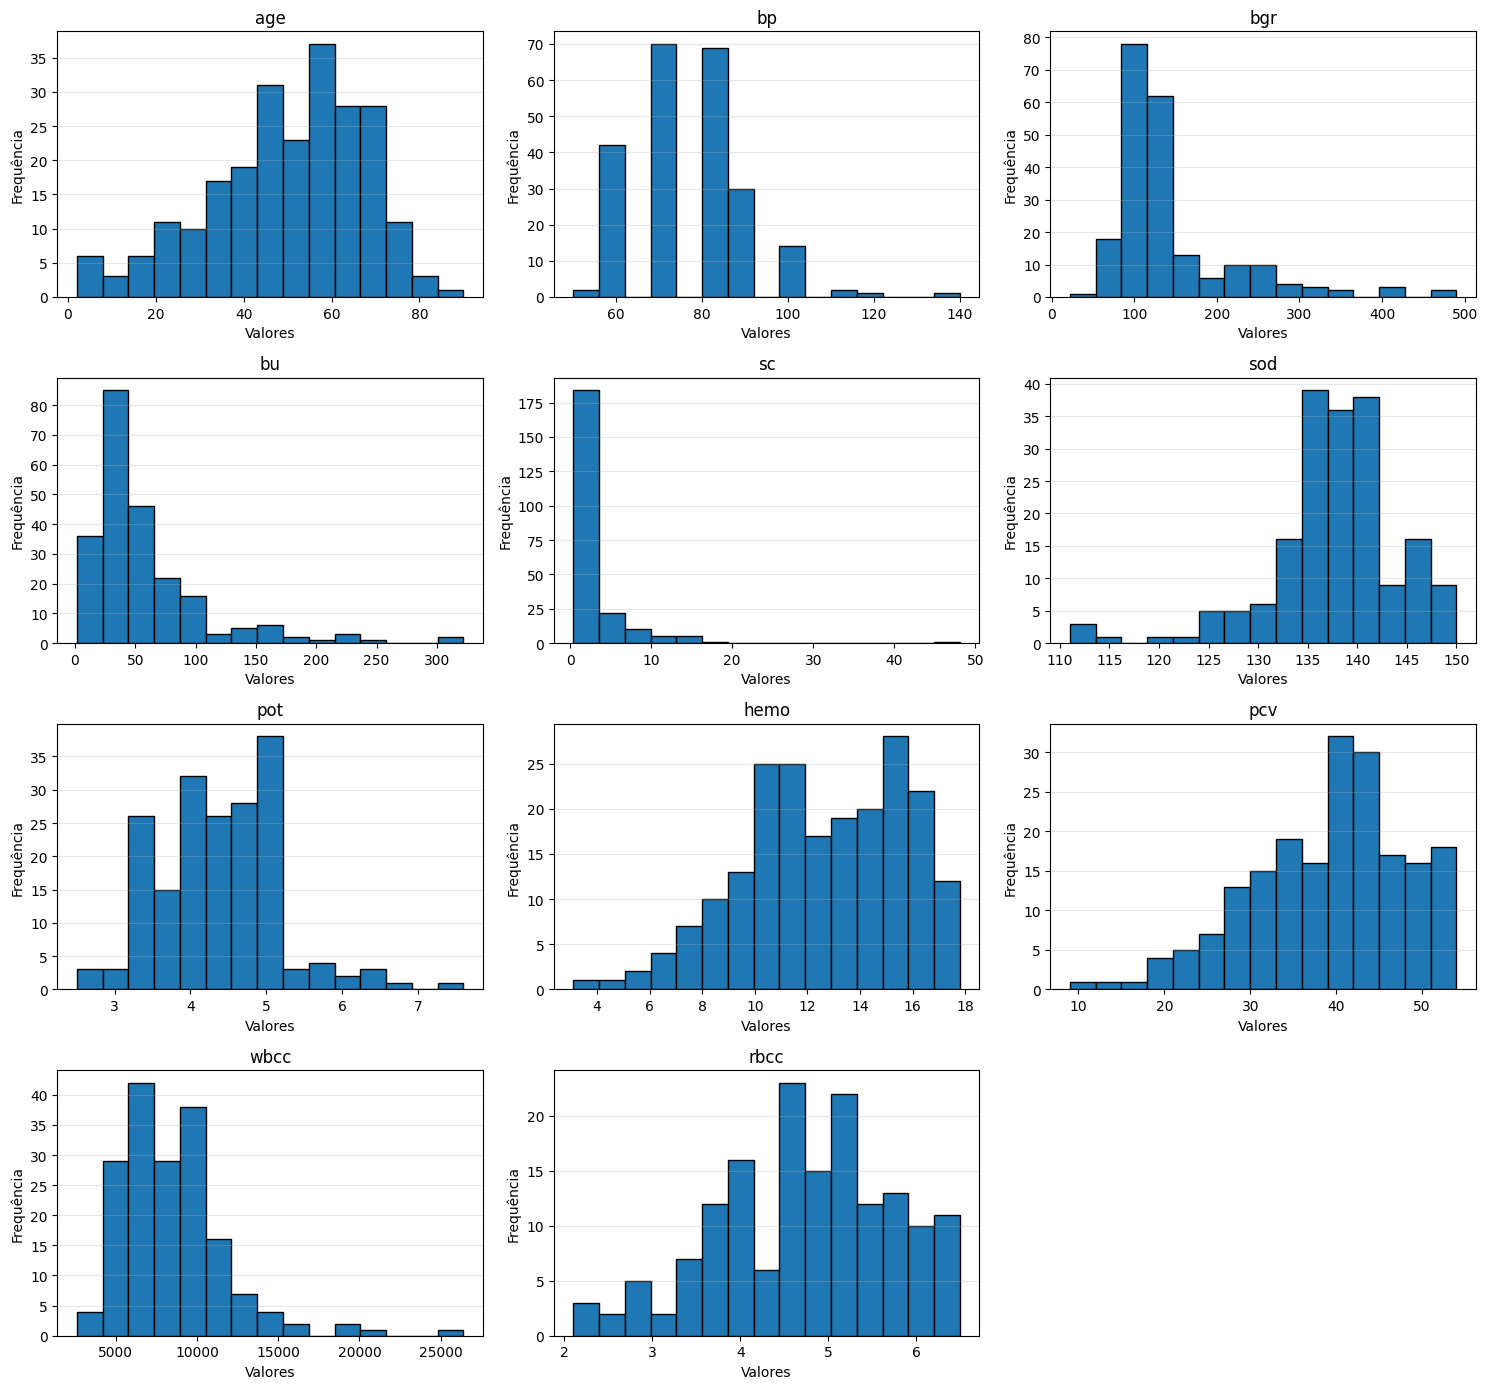

In [ ]:

# Cria os histogramas dos atributos numéricos
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(num):
    valores = X_train[col].dropna()

    axes[i].hist(valores, bins=15, edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel('Valores')
    axes[i].set_ylabel('Frequência')
    axes[i].grid(axis='y', alpha=0.3)

# Remove o espaço não utilizado
for ax in axes[len(num):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


### Resultados da distribuição dos atributos numéricos

Os histogramas mostraram diferentes padrões de distribuição entre os atributos. A variável `age` apresentou maior concentração de registros entre aproximadamente 40 e 70 anos, enquanto `bp` concentrou grande parte das observações entre 60 e 90.

As variáveis `bgr`, `bu` e `sc` apresentaram distribuições assimétricas à direita, com maior concentração de valores nas faixas inferiores e algumas observações bastante elevadas. Esse comportamento foi especialmente evidente em `sc`, que apresentou valores concentrados abaixo de 5, mas também registros que alcançaram 48,1.

Nas variáveis `sod` e `pot`, observamos maior concentração dos valores em intervalos relativamente estreitos, principalmente entre 135 e 145 para `sod` e entre 3,5 e 5,2 para `pot`.

Já `hemo` e `pcv` apresentaram maior concentração nas faixas intermediárias, enquanto `wbcc` demonstrou uma distribuição assimétrica, com algumas observações bastante elevadas. A variável `rbcc` apresentou valores distribuídos principalmente entre aproximadamente 3 e 6.

Esses resultados mostram que os atributos possuem escalas e distribuições distintas. As assimetrias e observações distantes das concentrações principais reforçam a importância de investigar possíveis valores atípicos e utilizar técnicas de pré-processamento adequadas.

### 4.4 Identificação de possíveis valores atípicos

Para investigar possíveis valores atípicos (*outliers*), utilizamos o intervalo interquartil (IQR), calculado pela diferença entre o terceiro e o primeiro quartil de cada variável.

Com base nessa medida, estabelecemos limites inferiores e superiores para identificar observações que se distanciam da distribuição central dos dados. Em seguida, contabilizamos os possíveis valores atípicos e calculamos seus percentuais em relação às observações disponíveis em cada atributo.

Os resultados foram organizados em uma tabela e representados por um gráfico de barras horizontais, facilitando a comparação entre as variáveis. Nesta etapa, as observações identificadas não foram removidas automaticamente, pois valores extremos podem representar características legítimas dos registros.

,Variável,Outliers,Observações,Percentual (%)
2,bgr,31,212,14.62
4,sc,29,228,12.72
3,bu,20,228,8.77
1,bp,20,231,8.66
5,sod,8,185,4.32
9,wbcc,6,175,3.43
0,age,6,234,2.56
6,pot,2,185,1.08
8,pcv,2,195,1.03
7,hemo,1,206,0.49


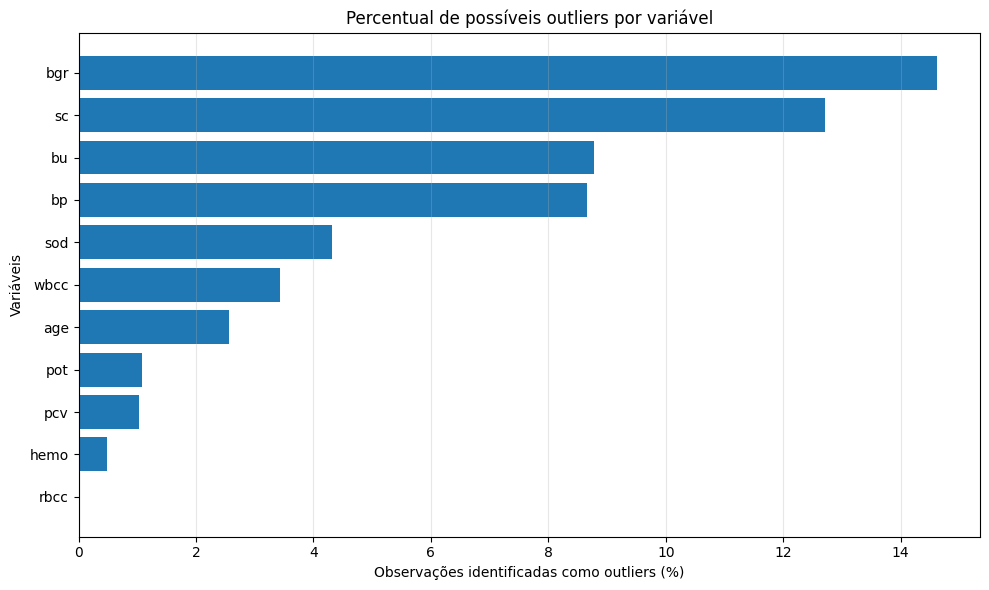

In [ ]:

# Identifica possíveis outliers utilizando o intervalo interquartil
resultados = []

for col in num:
    valores = X_train[col].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = ((valores < limite_inferior) |
                (valores > limite_superior)).sum()

    resultados.append({
        'Variável': col,
        'Outliers': int(outliers),
        'Observações': len(valores),
        'Percentual (%)': round(outliers / len(valores) * 100, 2)
    })

# Organiza os resultados do maior para o menor percentual
resultado_outliers = pd.DataFrame(resultados).sort_values(
    'Percentual (%)', ascending=False
)

display(resultado_outliers)

# Cria o gráfico de barras
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    resultado_outliers['Variável'],
    resultado_outliers['Percentual (%)']
)

ax.invert_yaxis()
ax.set_title('Percentual de possíveis outliers por variável')
ax.set_xlabel('Observações identificadas como outliers (%)')
ax.set_ylabel('Variáveis')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Salva os resultados
resultado_outliers.to_csv(
    OUT / 'analise_outliers.csv',
    index=False,
    encoding='utf-8'
)


### Resultados da identificação de possíveis valores atípicos

Os resultados apontaram maior concentração de possíveis valores atípicos nas variáveis `bgr` (14,62%) e `sc` (12,72%), seguidas por `bu` (8,77%) e `bp` (8,66%).

Em contrapartida, `hemo` apresentou apenas 0,49% de possíveis valores atípicos, enquanto `rbcc` não apresentou ocorrências segundo o critério utilizado.

Esses resultados indicam que algumas variáveis possuem maior quantidade de observações fora dos limites estabelecidos pelo intervalo interquartil. Entretanto, não removemos esses registros, pois eles podem representar características legítimas dos pacientes, e não necessariamente erros de preenchimento.

### 4.5 Análise de correlação

Para investigar as relações entre os atributos numéricos, calculamos a correlação de Pearson utilizando os dados de treinamento. O coeficiente permite identificar a intensidade e a direção da relação linear entre duas variáveis, apresentando valores entre -1 e +1.

Os resultados foram organizados em uma matriz e representados por um mapa de calor (*heatmap*). Utilizamos `imshow()` para converter os coeficientes em cores e `colorbar()` para apresentar a escala de intensidade. Também inserimos os valores numéricos em cada posição da matriz, facilitando a identificação das relações entre os atributos.

Valores positivos indicam que duas variáveis tendem a aumentar juntas, enquanto valores negativos indicam uma relação inversa. Já valores próximos de zero representam pouca associação linear.

A análise permite identificar relações entre os atributos e possíveis redundâncias nas informações. Entretanto, a correlação não demonstra que uma variável causa alterações na outra, e seus resultados devem ser interpretados considerando possíveis valores atípicos e informações ausentes.

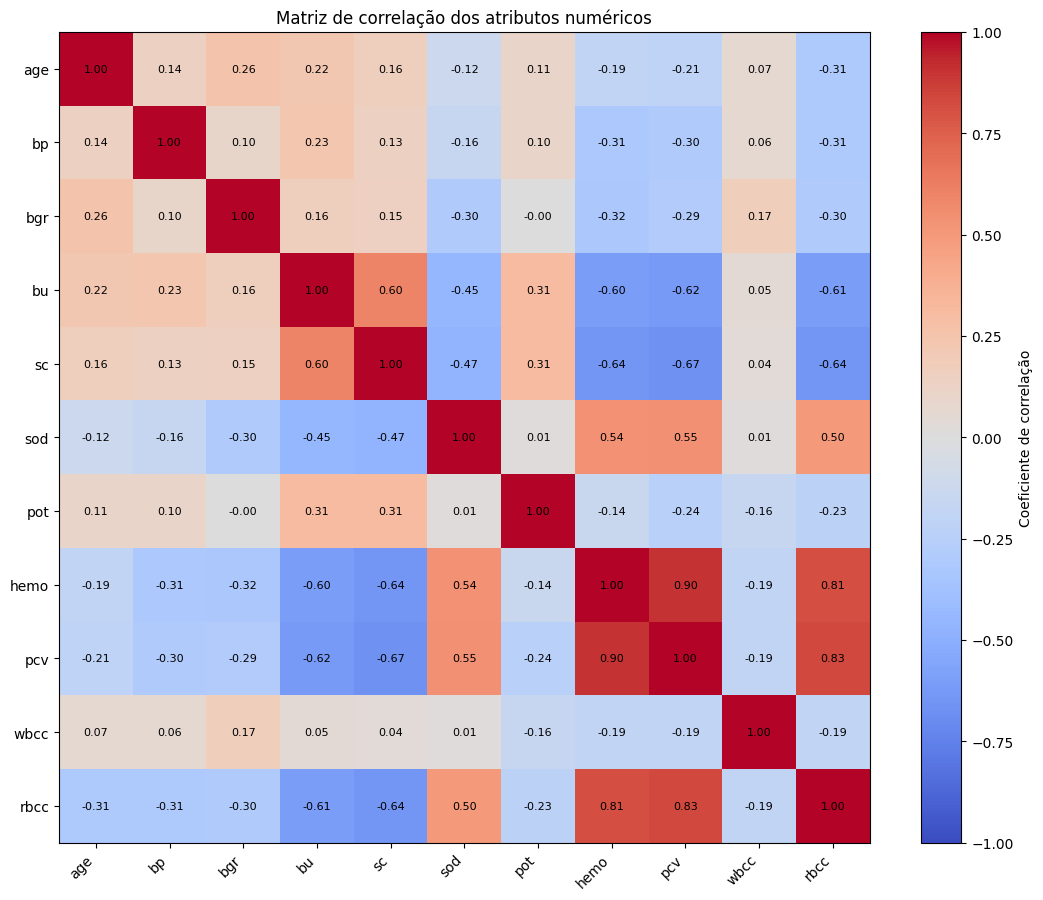

In [ ]:

# Calcula a correlação de Pearson
correlacao = X_train[num].corr(method='pearson')

# Cria o mapa de calor
fig, ax = plt.subplots(figsize=(11, 9))
imagem = ax.imshow(correlacao, cmap='coolwarm', vmin=-1, vmax=1)

fig.colorbar(imagem, ax=ax, label='Coeficiente de correlação')

# Identifica as variáveis nos eixos
posicoes = np.arange(len(num))
ax.set_xticks(posicoes)
ax.set_xticklabels(num, rotation=45, ha='right')
ax.set_yticks(posicoes)
ax.set_yticklabels(num)

# Exibe os coeficientes na matriz
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{correlacao.iloc[i, j]:.2f}',
                ha='center', va='center', fontsize=8)

ax.set_title('Matriz de correlação dos atributos numéricos')

plt.tight_layout()
plt.show()

# Salva a matriz
correlacao.to_csv(OUT / 'matriz_correlacao.csv', encoding='utf-8')


### Interpretação da matriz de correlação

A matriz apresentou correlações positivas fortes entre `hemo` e `pcv` (0,90), `pcv` e `rbcc` (0,83) e `hemo` e `rbcc` (0,81). Esses resultados indicam que essas variáveis tendem a apresentar comportamentos semelhantes.

Também identificamos uma correlação positiva entre `bu` e `sc` (0,60). Entre as relações negativas, destacaram-se `sc` e `pcv` (-0,67), `sc` e `hemo` (-0,64), `sc` e `rbcc` (-0,64) e `bu` e `pcv` (-0,62).

A variável `sod` também apresentou correlações positivas com `pcv` (0,55), `hemo` (0,54) e `rbcc` (0,50), além de relações negativas com `sc` (-0,47) e `bu` (-0,45).

Essas associações mostram que determinados atributos compartilham informações relacionadas, aspecto importante para a construção e interpretação dos modelos. Entretanto, a correlação representa apenas uma relação linear entre as variáveis e não demonstra que uma delas cause alterações na outra.

### 4.6 Distribuição dos valores ausentes

Reunimos os valores ausentes dos atributos numéricos e categóricos em uma única análise, calculando a quantidade e o percentual de informações não preenchidas em cada variável.

Utilizamos `isna().sum()` para contabilizar as ausências e `isna().mean()` para calcular sua proporção em relação aos registros de treinamento. Em seguida, organizamos os resultados em ordem decrescente e construímos um gráfico de barras horizontais, facilitando a identificação dos atributos mais afetados.

Essa visualização permite comparar a quantidade de informações incompletas entre as variáveis e identificar quais exigirão maior atenção durante o pré-processamento. Nesta etapa, os registros foram mantidos, sem realizar o preenchimento ou a exclusão dos valores ausentes.

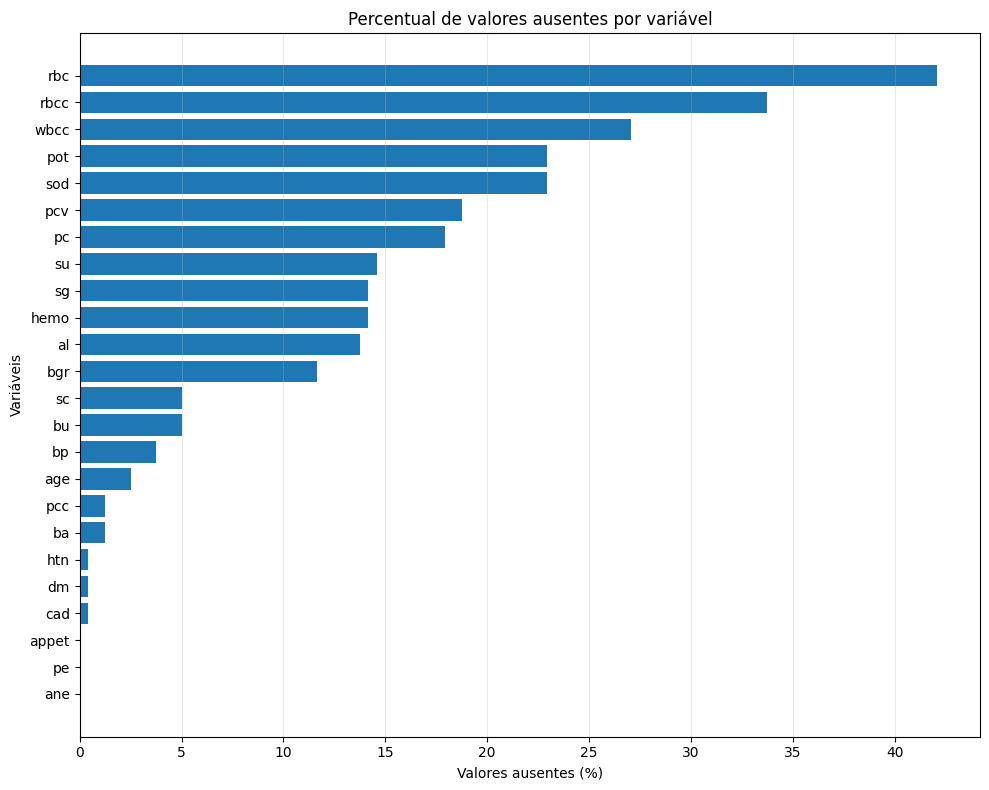

In [ ]:

# Calcula a quantidade e o percentual de valores ausentes
ausencias = pd.DataFrame({
    'Quantidade': X_train.isna().sum(),
    'Percentual (%)': X_train.isna().mean() * 100
}).sort_values('Percentual (%)', ascending=False).round(2)

# Cria o gráfico de barras horizontais
fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(ausencias.index, ausencias['Percentual (%)'])
ax.invert_yaxis()
ax.set_title('Percentual de valores ausentes por variável')
ax.set_xlabel('Valores ausentes (%)')
ax.set_ylabel('Variáveis')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Salva os resultados
ausencias.to_csv(
    OUT / 'valores_ausentes_treino.csv',
    encoding='utf-8',
    index_label='Variável'
)


### Resultados da análise de valores ausentes

Os resultados mostraram que a variável `rbc` apresentou o maior percentual de informações ausentes (42,08%), seguida por `rbcc` (33,75%) e `wbcc` (27,08%). Também observamos percentuais relevantes em `pot` e `sod`, ambos com 22,92% de ausências.

Em contrapartida, variáveis como `appet`, `pe` e `ane` não apresentaram campos sem preenchimento no conjunto de treinamento.

Essa diferença demonstra que a ausência de informações não ocorre de maneira uniforme entre os atributos. Por isso, o tratamento deverá considerar as características e a quantidade de dados disponíveis em cada variável, evitando a perda desnecessária de registros.

### 4.7 Distribuição da variável-alvo

Analisamos a distribuição da variável-alvo (`class`) para verificar a proporção entre os registros classificados como `ckd` e `notckd`.

Como as classificações foram convertidas para valores numéricos durante a divisão dos dados, utilizamos `map()` para identificar novamente cada classe. Em seguida, contabilizamos suas ocorrências com `value_counts()` e calculamos os respectivos percentuais em relação ao conjunto de treinamento.

Os resultados foram apresentados em uma tabela e em um gráfico de barras, permitindo visualizar a quantidade de registros de cada classe e identificar possíveis diferenças na distribuição.

Essa análise é importante para compreender o balanceamento da base e orientar a escolha das métricas utilizadas na avaliação dos modelos, evitando que a acurácia seja considerada isoladamente.

,Quantidade,Percentual (%)
class,,
ckd,150,62.5
notckd,90,37.5


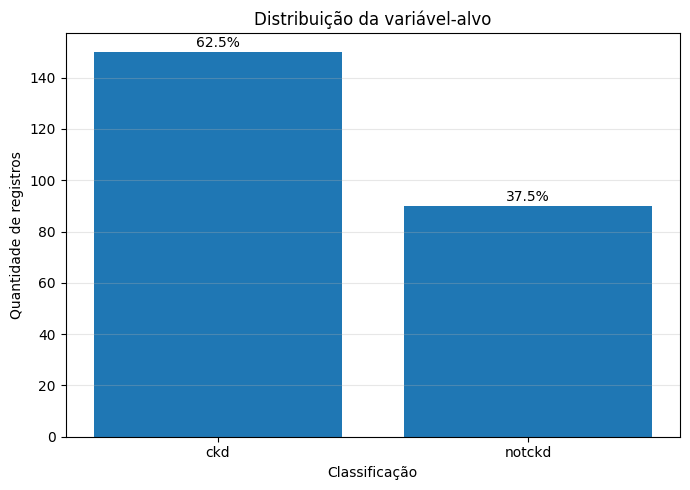

In [ ]:

# Identifica as classes e contabiliza suas ocorrências
classes = (
    y_train.map({1: 'ckd', 0: 'notckd'})
    .value_counts()
    .reindex(['ckd', 'notckd'], fill_value=0)
)

# Calcula a quantidade e o percentual
resumo_classes = pd.DataFrame({
    'Quantidade': classes,
    'Percentual (%)': (classes / len(y_train) * 100).round(2)
})

display(resumo_classes)

# Cria o gráfico de distribuição
fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(resumo_classes.index, resumo_classes['Quantidade'])

for i, barra in enumerate(barras):
    percentual = resumo_classes['Percentual (%)'].iloc[i]
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 2,
        f'{percentual:.1f}%',
        ha='center'
    )

ax.set_title('Distribuição da variável-alvo')
ax.set_xlabel('Classificação')
ax.set_ylabel('Quantidade de registros')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Salva os resultados
resumo_classes.to_csv(
    OUT / 'distribuicao_variavel_alvo.csv',
    encoding='utf-8'
)


### Resultados da distribuição da variável-alvo

Os resultados mostraram que 150 registros (62,5%) pertencem à classe `ckd`, enquanto 90 registros (37,5%) pertencem à classe `notckd`.

O gráfico evidencia uma predominância da classe `ckd`, com uma diferença de 25 pontos percentuais entre as duas categorias. Embora as classes não apresentem a mesma proporção, essa distribuição não representa um desbalanceamento extremo.

Essa característica deverá ser considerada durante a avaliação dos modelos. Por isso, além da acurácia, serão observadas métricas como precisão, revocação, F1-score e acurácia balanceada, permitindo avaliar o desempenho na identificação das duas classes.

## 5. Pré-processamento dos dados

O pré-processamento prepara os dados para utilização nos modelos de aprendizagem de máquina. Para os atributos numéricos, utilizamos a mediana para preencher os valores ausentes e o `RobustScaler` para ajustar as escalas, reduzindo a influência de possíveis valores extremos. Para os atributos categóricos, utilizamos a categoria mais frequente no preenchimento das ausências e o *One-Hot Encoding* para convertê-los em representações numéricas.

A codificação cria indicadores para as categorias sem estabelecer uma ordem artificial entre elas. Entretanto, sua aplicação às variáveis `sg`, `al` e `su`, que possuem níveis ordenados, não preserva explicitamente essa informação ordinal.

Organizamos essas transformações com `Pipeline` e `ColumnTransformer`, ajustando os procedimentos exclusivamente com os dados de treinamento e aplicando-os posteriormente à validação e ao teste. Essa separação evita o vazamento de informações (*data leakage*). Também utilizamos `handle_unknown='ignore'` para lidar com categorias não encontradas durante o treinamento.

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# Tratamento dos atributos numéricos
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Tratamento dos atributos categóricos
pipeline_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Reúne os dois processos
preprocessor = ColumnTransformer([
    ('num', pipeline_num, num),
    ('cat', pipeline_cat, cat)
])

# Ajusta no treinamento e aplica aos demais conjuntos
X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

print('Dimensões após o pré-processamento:')
print('Treinamento:', X_train_prepared.shape)
print('Validação:', X_val_prepared.shape)
print('Teste:', X_test_prepared.shape)


Dimensões após o pré-processamento:
Treinamento: (240, 48)
Validação: (80, 48)
Teste: (80, 48)


### Resultado do pré-processamento

Após a aplicação das transformações, obtivemos 240 registros de treinamento, 80 de validação e 80 de teste, todos com 48 atributos.

O aumento de 24 para 48 colunas ocorreu devido à codificação *One-Hot Encoding*, que transformou as variáveis categóricas em 37 colunas indicadoras, mantendo os 11 atributos numéricos.

A quantidade de registros foi preservada, e os três conjuntos passaram a apresentar a mesma estrutura, permitindo sua utilização nos modelos de aprendizagem de máquina.

### 5.1 Verificação dos dados após o pré-processamento

Após as transformações, verificamos se os conjuntos permaneceram com suas dimensões esperadas e se todos os valores foram convertidos corretamente.

Também conferimos os nomes dos atributos gerados pelo *One-Hot Encoding*, identificando quais colunas correspondem aos dados numéricos originais e quais foram criadas a partir das categorias.

Por fim, verificamos a existência de valores ausentes ou não finitos após o tratamento. Essas conferências ajudam a garantir que os dados estejam consistentes e prontos para serem utilizados no treinamento dos modelos.

In [ ]:

from scipy import sparse

# Identifica os nomes dos atributos após a transformação
nomes_atributos = preprocessor.get_feature_names_out()

conjuntos = {
    'Treinamento': X_train_prepared,
    'Validação': X_val_prepared,
    'Teste': X_test_prepared
}

# Verifica dimensões e valores não finitos
for nome, dados in conjuntos.items():
    valores = dados.data if sparse.issparse(dados) else dados

    assert np.isfinite(valores).all(), (
        f'Foram encontrados valores não finitos em {nome}.'
    )
    assert dados.shape[1] == len(nomes_atributos)

    print(f'{nome}: {dados.shape} — verificação concluída.')

# Separa a quantidade de atributos por tipo
num_gerados = sum(n.startswith('num__') for n in nomes_atributos)
cat_gerados = sum(n.startswith('cat__') for n in nomes_atributos)

print('\nAtributos numéricos:', num_gerados)
print('Atributos categóricos codificados:', cat_gerados)
print('Total de atributos:', len(nomes_atributos))

# Exibe os nomes das colunas geradas
display(pd.DataFrame({'Atributos gerados': nomes_atributos}))


Treinamento: (240, 48) — verificação concluída.
Validação: (80, 48) — verificação concluída.
Teste: (80, 48) — verificação concluída.

Atributos numéricos: 11
Atributos categóricos codificados: 37
Total de atributos: 48


,Atributos gerados
0,num__age
1,num__bp
2,num__bgr
3,num__bu
4,num__sc
5,num__sod
6,num__pot
7,num__hemo
8,num__pcv
9,num__wbcc


### Resultado da verificação do pré-processamento

As verificações confirmaram que os três conjuntos foram transformados corretamente, mantendo suas quantidades originais de registros e apresentando 48 atributos cada.

Do total de atributos, 11 correspondem às variáveis numéricas originais e 37 foram gerados pelo *One-Hot Encoding*, representando as categorias das variáveis categóricas.

Também verificamos que não existem valores ausentes ou não finitos após as transformações. Com isso, confirmamos que os dados estão estruturados e preparados para serem utilizados no treinamento dos modelos.

## 6. Modelo de referência (Baseline)

Após concluir o pré-processamento, desenvolvemos um modelo de referência (*baseline*) utilizando o `DummyClassifier`, do Scikit-learn, com a estratégia `most_frequent`. Esse classificador realiza todas as previsões com base na classe mais frequente nos dados de treinamento, sem identificar relações entre os atributos e a variável-alvo.

Para avaliar seu desempenho, utilizamos diferentes métricas de classificação. A acurácia representa a proporção geral de previsões corretas, enquanto a acurácia balanceada considera o desempenho na identificação de cada classe. Também calculamos a precisão, o *recall* e o F1-score, que permitem analisar diferentes aspectos dos acertos e erros do classificador. A especificidade complementa essa avaliação, indicando a proporção de registros `notckd` corretamente identificados.

Damos atenção especial ao *recall* da classe `ckd`, pois um falso negativo ocorre quando um registro classificado como `ckd` é previsto como `notckd`, podendo deixar de sinalizar um caso que mereceria atenção em um cenário hipotético de triagem. Já o falso positivo ocorre quando um registro `notckd` é classificado como `ckd`, podendo gerar uma sinalização ou revisão desnecessária.

Essa escolha considera que os dois tipos de erro possuem consequências diferentes. Por isso, avaliamos a capacidade de identificar a classe `ckd` sem deixar de observar a precisão e a especificidade. O baseline estabelece uma referência inicial para verificar se os algoritmos desenvolvidos posteriormente conseguem aprender padrões úteis e apresentar resultados superiores a uma classificação baseada apenas na classe predominante.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

# Treina o classificador de referência
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_prepared, y_train)

# Realiza as previsões no conjunto de validação
y_pred_baseline = baseline.predict(X_val_prepared)

# Calcula as métricas de avaliação
metricas_baseline = pd.DataFrame({
    'Acurácia': [accuracy_score(y_val, y_pred_baseline)],
    'Acurácia balanceada': [
        balanced_accuracy_score(y_val, y_pred_baseline)
    ],
    'Precisão (CKD)': [
        precision_score(y_val, y_pred_baseline, zero_division=0)
    ],
    'Recall (CKD)': [
        recall_score(y_val, y_pred_baseline, pos_label=1)
    ],
    'F1-score (CKD)': [
        f1_score(y_val, y_pred_baseline, pos_label=1)
    ],
    'Especificidade (notCKD)': [
        recall_score(y_val, y_pred_baseline, pos_label=0)
    ]
}, index=['Baseline']).round(3)

# Calcula e organiza a matriz de confusão
matriz = confusion_matrix(
    y_val,
    y_pred_baseline,
    labels=[0, 1]
)

matriz_confusao = pd.DataFrame(
    matriz,
    index=['Real: notckd', 'Real: ckd'],
    columns=['Previsto: notckd', 'Previsto: ckd']
)

# Apresenta os resultados
print('MÉTRICAS DO BASELINE')
display(metricas_baseline)

print('MATRIZ DE CONFUSÃO')
display(matriz_confusao)

# Salva os resultados
metricas_baseline.to_csv(OUT / 'metricas_baseline.csv')
matriz_confusao.to_csv(OUT / 'matriz_confusao_baseline.csv')

MÉTRICAS DO BASELINE


,Acurácia,Acurácia balanceada,Precisão (CKD),Recall (CKD),F1-score (CKD),Especificidade (notCKD)
Baseline,0.625,0.5,0.625,1.0,0.769,0.0


MATRIZ DE CONFUSÃO


,Previsto: notckd,Previsto: ckd
Real: notckd,0,30
Real: ckd,0,50


### 6.1 Resultados da avaliação do baseline

O baseline apresentou acurácia de 62,5%, acurácia balanceada de 50%, precisão de 62,5%, *recall* de 100% para a classe `ckd`, F1-score de aproximadamente 76,9% e especificidade de 0% para a classe `notckd`.

Ao analisar a matriz de confusão, identificamos que o classificador realizou todas as previsões como `ckd`. Dessa forma, acertou os 50 registros dessa classe, mas classificou incorretamente os 30 registros `notckd`.

Esse comportamento ocorreu porque a estratégia `most_frequent` utiliza exclusivamente a classe mais frequente nos dados de treinamento, sem aprender relações entre os atributos e a variável-alvo.

Embora tenha alcançado 62,5% de acurácia, o modelo não conseguiu distinguir as duas classes. A acurácia balanceada de 50% e a especificidade de 0% evidenciam essa limitação, demonstrando que uma boa acurácia geral não significa necessariamente um bom desempenho na identificação de todas as categorias.

O baseline estabelece, portanto, uma referência inicial para comparar os modelos mais complexos que serão desenvolvidos nas próximas etapas.